<a href="https://colab.research.google.com/github/sudenazgrmz/TechSupportPortal/blob/main/01_train_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Haber grubu metinleri: bilgisayar ve spor konularını ayırt etmeye çalışacağız
kategoriler = ["comp.graphics", "rec.sport.baseball"]
veri = fetch_20newsgroups(subset="all", categories=kategoriler,
                          remove=("headers", "footers", "quotes"))
metinler, etiketler = veri.data, veri.target
print("Toplam örnek:", len(metinler))

# Veriyi böl: %80 eğitim, %20 test
X_egitim, X_test, y_egitim, y_test = train_test_split(
    metinler, etiketler, test_size=0.2, random_state=42, stratify=etiketler
)

# Metni sayılara çevir (TF-IDF) ve modeli eğit
vektor = TfidfVectorizer(max_features=5000)
X_egitim_v = vektor.fit_transform(X_egitim)
X_test_v = vektor.transform(X_test)

model = LogisticRegression(max_iter=1000)
model.fit(X_egitim_v, y_egitim)

print("Eğitim doğruluğu:", accuracy_score(y_egitim, model.predict(X_egitim_v)))
print("Test doğruluğu:  ", accuracy_score(y_test, model.predict(X_test_v)))

Toplam örnek: 1967
Eğitim doğruluğu: 0.9758423394787031
Test doğruluğu:   0.9365482233502538


                    precision    recall  f1-score   support

     comp.graphics       0.94      0.93      0.94       195
rec.sport.baseball       0.93      0.94      0.94       199

          accuracy                           0.94       394
         macro avg       0.94      0.94      0.94       394
      weighted avg       0.94      0.94      0.94       394



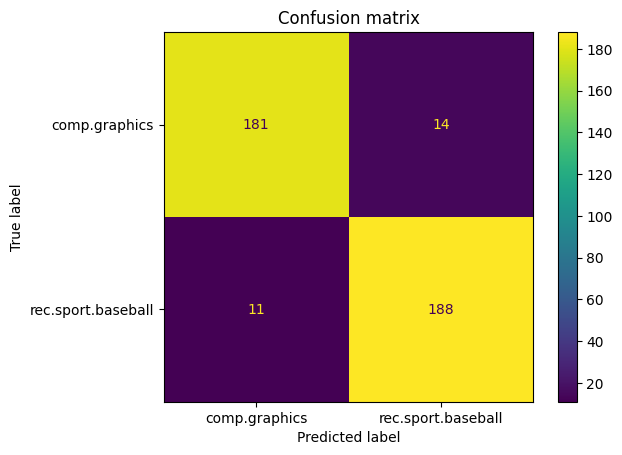

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

tahmin = model.predict(X_test_v)

print(classification_report(y_test, tahmin, target_names=veri.target_names))

ConfusionMatrixDisplay.from_predictions(y_test, tahmin, display_labels=veri.target_names)
plt.title("Confusion matrix")
plt.show()

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, classification_report

rng = np.random.default_rng(42)
y_arr = np.array(y_test)

idx_graphics = np.where(y_arr == 0)[0]
idx_baseball = np.where(y_arr == 1)[0]
idx_baseball_az = rng.choice(idx_baseball, size=10, replace=False)

idx = np.concatenate([idx_graphics, idx_baseball_az])
X_dengesiz = X_test_v[idx]
y_dengesiz = y_arr[idx]

tahmin_model = model.predict(X_dengesiz)
tahmin_aptal = np.zeros_like(y_dengesiz)  # herkese "graphics" (0) der

for ad, t in [("Model", tahmin_model), ("Aptal (hep 0)", tahmin_aptal)]:
    print(ad, "-> accuracy:", round(accuracy_score(y_dengesiz, t), 3),
          "| macro-F1:", round(f1_score(y_dengesiz, t, average="macro"), 3))

print("\n--- Model ---")
print(classification_report(y_dengesiz, tahmin_model, target_names=veri.target_names))
print("--- Aptal model ---")
print(classification_report(y_dengesiz, tahmin_aptal, target_names=veri.target_names, zero_division=0))

Model -> accuracy: 0.927 | macro-F1: 0.753
Aptal (hep 0) -> accuracy: 0.951 | macro-F1: 0.487

--- Model ---
                    precision    recall  f1-score   support

     comp.graphics       0.99      0.93      0.96       195
rec.sport.baseball       0.39      0.90      0.55        10

          accuracy                           0.93       205
         macro avg       0.69      0.91      0.75       205
      weighted avg       0.97      0.93      0.94       205

--- Aptal model ---
                    precision    recall  f1-score   support

     comp.graphics       0.95      1.00      0.97       195
rec.sport.baseball       0.00      0.00      0.00        10

          accuracy                           0.95       205
         macro avg       0.48      0.50      0.49       205
      weighted avg       0.90      0.95      0.93       205

